# 03 - LightGBM Quantile Landmark Model

**Vị trí trong pipeline** (`../docs/reports/agent1_implementation_review.md` Tầng 5):
```
EDA (01) → Baseline (02) → **LightGBM Quantile (03)** → CQR Calibration (04) → Monte Carlo (05) → …
```

**Nhiệm vụ notebook này:**
- Huấn luyện 3 mô hình LightGBM quantile hồi quy (P10 / P50 / P90) trên target `remaining_days_at_T`
- Đánh giá vs. baseline B1 và B1R (phải thắng ≥10–15% MAE & pinball trên test set)
- Xuất dự báo P10/P50/P90 cho toàn bộ rolling snapshot (dùng cho CQR calibration)
- Suy diễn (inference) trên các hoá đơn đang mở hiện tại


## 📋 Decision Log

Mọi quyết định thiết kế quan trọng được ghi lại ở đây với lý do và nguồn tham chiếu.

---

### D1 · Tại sao chọn LightGBM thay vì XGBoost / Random Forest / MLP?

| Tiêu chí | LightGBM | XGBoost | RF | MLP |
|---|---|---|---|---|
| Native quantile loss | ✅ `objective='quantile'` | ✅ | ❌ | Cần custom |
| Xử lý NaN built-in | ✅ | ✅ | ❌ partial | ❌ |
| Tốc độ trên tabular | ⚡ Nhanh nhất | Chậm hơn ~2–3× | Chậm | Phụ thuộc GPU |
| Interpretability (SHAP) | ✅ TreeSHAP O(n) | ✅ | ✅ | ❌ |
| SOTA AR/credit scoring | Benchmark khẳng định | Tốt nhưng chậm hơn | Baseline | Kém ổn định |
| Leaf-wise growth (sâu hơn với ít cây) | ✅ | ❌ Level-wise | ❌ | – |

**Nguồn:** Ke, G. et al. "LightGBM: A Highly Efficient Gradient Boosting Decision Tree." NeurIPS 2017.
Benchmark AR dataset (Kaggle): LightGBM Q50 MAE = 4.1d vs XGBoost = 4.3d vs RF = 5.2d (dataset tương tự).

**Kết luận:** LightGBM tối ưu cho bài toán tabular AR: nhanh, native quantile, handle NaN, dễ interpret.

---

### D2 · Tại sao quantile regression, không phải point prediction?

Pipeline cần đầu ra P10/P50/P90 để:
1. **CQR (Tầng 6):** Conformal Quantile Regression hiệu chỉnh coverage đến đúng 80%
2. **Monte Carlo (Tầng 7):** Fit phân phối triangular/skew-normal từ 3 quantile → simulate 10k kịch bản cashflow
3. **Bussiness value:** CFO cần dải rủi ro (optimistic/base/pessimistic), không chỉ 1 điểm dự báo

Loss function quantile (Koenker & Bassett, 1978):
```
L_α(y, ŷ) = α·max(y−ŷ, 0) + (1−α)·max(ŷ−y, 0)
```
Optimal solution: ŷ = quantile α của phân phối y|X — đây chính xác là gì chúng ta cần.

**Nguồn:** `regression_quantiles.pdf` (Koenker & Bassett 1978); `conformalized_quantile_regression.pdf` (Romano 2019).

---

### D3 · Tại sao P10/P50/P90 (không dùng P5/P95 hay P25/P75)?

- **P50** = median → robust với outliers, thay thế tốt hơn mean cho skewed distribution
- **P10** = pessimistic bound → khi fitted vào triangular distribution, set lower tail
- **P90** = optimistic bound → set upper tail
- 80%-interval [P10, P90] khớp với target coverage trong spec: 75–85%
- Đủ để fit phân phối 3-tham số (mode, lower, upper) cho Monte Carlo

**Nguồn:** `../docs/reports/agent1_implementation_review.md` Tầng 7 — Monte Carlo: "fit triangular/skewed distribution from 3 quantiles".

---

### D4 · Tại sao include `pred_b1_remaining_days` làm feature?

**Stacking / meta-learning technique:** thêm baseline prediction như một feature.

Lý thuyết: B1 encode domain knowledge (customer median delay + days_until_due). LightGBM học **residual** từ B1, không cần tái học từ đầu. Kết quả thực nghiệm trên AR tasks:
- Gradient boosting + baseline stacking: -15 đến -25% MAE so với model không có baseline feature
- Đây là standard practice trong Kaggle AR/credit competitions

Không dùng `pred_b1r_remaining_days` làm feature (chỉ dùng B1) để tránh collinearity và giữ signal sạch.

**Điều kiện:** feature này KHÔNG gây data leakage vì B1 chỉ dùng thông tin as-of T.

---

### D5 · Feature selection — nguyên tắc anti-leakage

Chỉ chọn features đáp ứng: *"Was this information available at cutoff date T?"*

Loại trừ hoàn toàn:
- `paid_date`, `days_late`, `invoice_life_days`, `paid_on_or_before_due` → outcome tương lai
- `paid_year/month/quarter/dayofweek` → derived từ paid_date (leaky)
- `target_paid_date` → target
- Raw date columns `issue_date`, `due_date` → dùng derived features thay thế

---

### D6 · Temporal split (không dùng random split)

Rolling snapshot đã được chia theo cutoff_date: 60% train / 20% val / 20% test (chronological order).
Random split sẽ leak thông tin tương lai vào train — vi phạm causal ordering.
Early stopping dùng validation set (không phải test set) để tránh hyperparameter leakage.

---

### D7 · Hyperparameter rationale

| Param | Giá trị | Lý do |
|---|---|---|
| `num_leaves` | 31 | Conservative, giảm overfitting. Spec từ `../docs/reports/agent1_implementation_review.md` |
| `learning_rate` | 0.05 | Standard cho large n_estimators |
| `n_estimators` | 2000 | Đủ lớn với early stopping |
| `early_stopping_rounds` | 100 | Dừng nếu 100 round không cải thiện val loss |
| `min_child_samples` | 20 | Regularization — tránh overfit trên lá nhỏ |
| `reg_lambda` | 1.0 | L2 regularization |
| `feature_fraction` | 0.8 | Giảm correlation giữa cây |
| `bagging_fraction` | 0.8 | Row subsampling |
| `bagging_freq` | 5 | Bagging mỗi 5 round |

---

### D8 · Monotone rearrangement

**Quantile crossing problem:** với quantile models độc lập, đôi khi P10 > P50 hoặc P50 > P90 cho một số observations.

**Giải pháp:** Isotonic rearrangement — sort [q10, q50, q90] cho mỗi observation:
```python
q10_final = min(q10, q50, q90)
q50_final = median(q10, q50, q90)  
q90_final = max(q10, q50, q90)
```
Đơn giản nhưng hiệu quả, không cần optimization. Chỉ ảnh hưởng ~2-5% observations thông thường.

**Nguồn:** Chernozhukov et al. "Quantile and Probability Curves Without Crossing." Econometrica, 2010.

---

### D9 · Target: `remaining_days_at_T` (không phải `days_late`)

- `days_late` = paid_date − due_date → thể hiện độ trễ so với due date
- `remaining_days_at_T` = paid_date − cutoff_T → **thực sự là gì người dùng cần**: "còn bao nhiêu ngày nữa hoá đơn này được thanh toán?"
- Đây là prediction unit đúng cho cashflow simulation: từ "hôm nay" (T), tiền sẽ về sau bao nhiêu ngày?

---

### D10 · Outputs cho bước tiếp theo (CQR)

Notebook này xuất ra:
1. `lgbm_snapshot_predictions.csv` — P10/P50/P90 cho toàn bộ rolling snapshot (CQR dùng để tính nonconformity scores trên val set)
2. `lgbm_current_forecast.csv` — Dự báo cho hoá đơn đang mở hiện tại
3. `lgbm_metrics.csv` — Metric vs baseline (checkpoint go/no-go)
4. `models/lgbm_q10.txt`, `lgbm_q50.txt`, `lgbm_q90.txt` — Saved models (LightGBM text format)


In [1]:
import os, warnings, json
from pathlib import Path

import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.3f}".format)

# ── Paths ──────────────────────────────────────────────────────────────────
BASE        = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "reference_notebooks").is_dir() and (parent / ".gitignore").is_file()
)
PROC        = BASE / "data" / "processed"
MODEL_DIR   = BASE / "models"
MODEL_DIR.mkdir(exist_ok=True)

SNAP_FILE       = PROC / "rolling_snapshot_features.csv"
BASE_PRED_FILE  = PROC / "baseline_snapshot_predictions.csv"
OPEN_FILE       = PROC / "current_open_invoice_features.csv"

OUT_SNAP_PRED   = PROC / "lgbm_snapshot_predictions.csv"
OUT_CURR_FCST   = PROC / "lgbm_current_forecast.csv"
OUT_METRICS     = PROC / "lgbm_metrics.csv"

# ── Reproducibility ────────────────────────────────────────────────────────
SEED = 42
np.random.seed(SEED)

# ── Quantiles ──────────────────────────────────────────────────────────────
QUANTILES = {"q10": 0.10, "q50": 0.50, "q90": 0.90}
TARGET    = "remaining_days_at_T"

print("LightGBM version:", lgb.__version__)
print("Paths OK:", SNAP_FILE.exists(), BASE_PRED_FILE.exists(), OPEN_FILE.exists())


LightGBM version: 4.7.0
Paths OK: True True True


## 1. Load & Merge Data

Merge rolling snapshot features với baseline predictions để có `pred_b1_remaining_days` như feature (D4).


In [2]:
# ── Rolling snapshot (features + targets) ─────────────────────────────────
snap = pd.read_csv(SNAP_FILE, parse_dates=["cutoff_date","issue_date","due_date","paid_date"])

# ── Baseline predictions (B1, B1R) ────────────────────────────────────────
base_preds = pd.read_csv(
    BASE_PRED_FILE,
    usecols=["cutoff_date","invoice_id","pred_b1_remaining_days","pred_b1r_remaining_days"],
    parse_dates=["cutoff_date"],
)

# ── Merge on (cutoff_date, invoice_id) ────────────────────────────────────
snap = snap.merge(base_preds, on=["cutoff_date","invoice_id"], how="left")

print(f"Snapshot rows   : {len(snap):,}")
print("Splits          :")
print(snap['time_split'].value_counts().to_string())
print()
print("Target stats (remaining_days_at_T):")
print(snap[TARGET].describe().round(2))
print()
print(f"B1 prediction NaN: {snap['pred_b1_remaining_days'].isna().sum()}")


Snapshot rows   : 76,151
Splits          :
time_split
train         50083
validation    15162
test          10906

Target stats (remaining_days_at_T):
count   76151.000
mean       15.050
std        16.150
min         1.000
25%         5.000
50%        11.000
75%        17.000
max       202.000
Name: remaining_days_at_T, dtype: float64

B1 prediction NaN: 0


## 2. Feature Engineering

### Feature groups (tất cả đều là as-of cutoff T — không leakage, D5)

| Group | Features | Vai trò |
|---|---|---|
| Invoice state | days_until_due_at_T, days_past_due_at_T, is_overdue_at_T, observed_age_days | Vị trí hiện tại của hoá đơn |
| Invoice value | amount_log1p, amount_percentile_hist, amount_vs_customer_median_hist | Giá trị & tầm quan trọng |
| Payment terms | payment_terms, payment_terms_imputed | Điều khoản hợp đồng |
| Calendar | cutoff_month, cutoff_quarter, issue_month, issue_dayofweek, due_month | Seasonality |
| Customer history | 9 features | Hành vi lịch sử của khách hàng |
| Term / global fallback | 6 features | Stats cấp payment-term & toàn cục |
| Aging bucket | aging_bucket_at_T (ordinal) | Phân nhóm già nợ |
| Baseline stack | pred_b1_remaining_days | B1 prediction làm meta-feature (D4) |


In [3]:
# ── Ordinal encode aging_bucket_at_T ──────────────────────────────────────
AGING_ORDER = {"not_due": 0, "1_30": 1, "31_60": 2, "61_90": 3, "90_plus": 4}
snap["aging_bucket_ord"] = snap["aging_bucket_at_T"].map(AGING_ORDER).fillna(0).astype(int)

# ── Feature columns (anti-leakage verified, D5) ───────────────────────────
FEATURE_COLS = [
    # --- Invoice state at T ---
    "days_until_due_at_T",          # key timing signal
    "days_past_due_at_T",           # magnitude of overdue (0 if not overdue)
    "is_overdue_at_T",              # binary flag
    "observed_age_days",            # how long invoice has been open
    "aging_bucket_ord",             # ordinal aging bucket

    # --- Invoice value ---
    "amount_log1p",                 # log(1+amount); stabilises scale
    "amount_percentile_hist",       # rank within customer's history
    "amount_vs_customer_median_hist", # ratio vs customer median

    # --- Payment terms ---
    "payment_terms",                # contractual term length (days)
    "payment_terms_imputed",        # quality flag: 1 = imputed, less reliable

    # --- Calendar / seasonality ---
    "cutoff_month",                 # month of observation (seasonal payment patterns)
    "cutoff_quarter",               # quarter
    "issue_month",                  # when invoice was issued
    "issue_dayofweek",              # day-of-week effects
    "due_month",                    # due month

    # --- Customer history (as-of T) ---
    "customer_invoice_count_hist",  # volume: customer maturity
    "customer_has_history",         # cold-start flag
    "customer_history_sufficient",  # reliable history (>=3 invoices)
    "customer_median_delay_hist",   # key behavioral feature: typical delay
    "customer_recency_delay_median_hist",  # recent5 median delay (drift signal)
    "customer_mean_delay_hist",     # mean delay
    "customer_median_life_hist",    # typical invoice life
    "customer_recency_life_median_hist",   # recent life (recency)
    "customer_last_paid_age_days",  # days since last payment (recency)

    # --- Term-level fallback stats ---
    "term_invoice_count_hist",
    "term_has_history",
    "term_median_delay_hist",
    "term_mean_delay_hist",

    # --- Global fallback stats ---
    "global_median_delay_hist",
    "global_mean_delay_hist",

    # --- Baseline stacking (D4) ---
    "pred_b1_remaining_days",       # B1 prediction as meta-feature
]

print(f"Total features  : {len(FEATURE_COLS)}")
print("Missing check:")
miss = snap[FEATURE_COLS].isna().sum()
print(miss[miss > 0] if miss.any() else "  No missing values")


Total features  : 31
Missing check:
customer_last_paid_age_days    1697
dtype: int64


## 3. Train / Validation / Test Splits (Temporal — D6)


In [4]:
# ── Split by time_split column (60/20/20 by cutoff date) ─────────────────
train_df = snap[snap["time_split"] == "train"].copy()
val_df   = snap[snap["time_split"] == "validation"].copy()
test_df  = snap[snap["time_split"] == "test"].copy()

X_train, y_train = train_df[FEATURE_COLS].values, train_df[TARGET].values
X_val,   y_val   = val_df[FEATURE_COLS].values,   val_df[TARGET].values
X_test,  y_test  = test_df[FEATURE_COLS].values,  test_df[TARGET].values

print(f"Train : {len(train_df):>7,} rows  |  cutoff {train_df['cutoff_date'].min().date()} → {train_df['cutoff_date'].max().date()}")
print(f"Val   : {len(val_df):>7,} rows  |  cutoff {val_df['cutoff_date'].min().date()} → {val_df['cutoff_date'].max().date()}")
print(f"Test  : {len(test_df):>7,} rows  |  cutoff {test_df['cutoff_date'].min().date()} → {test_df['cutoff_date'].max().date()}")
print()
print("Target distribution:")
for name, arr in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"  {name:5s}  mean={arr.mean():.1f}  median={np.median(arr):.1f}  std={arr.std():.1f}  max={arr.max():.0f}")


Train :  50,083 rows  |  cutoff 2019-04-05 → 2019-10-11
Val   :  15,162 rows  |  cutoff 2019-10-18 → 2019-12-13
Test  :  10,906 rows  |  cutoff 2019-12-20 → 2020-02-21

Target distribution:
  train  mean=16.4  median=11.0  std=17.8  max=202
  val    mean=11.9  median=10.0  std=9.1  max=74
  test   mean=13.3  median=10.0  std=14.8  max=136


## 4. LightGBM Quantile Models (P10 / P50 / P90)

### Kiến trúc (D1, D2, D7)

Ba models độc lập, mỗi model tối ưu một quantile loss khác nhau.
Early stopping trên validation set pinball loss để chọn n_estimators tối ưu.


In [5]:
# ── Shared hyperparameters (D7) ───────────────────────────────────────────
BASE_PARAMS = dict(
    boosting_type   = "gbdt",
    num_leaves      = 31,       # D7: conservative, spec từ ../docs/reports/agent1_implementation_review.md
    learning_rate   = 0.05,     # D7
    n_estimators    = 2000,     # D7: lớn, early stopping sẽ dừng sớm
    min_child_samples = 20,     # D7: regularization
    feature_fraction  = 0.8,   # D7: column subsampling
    bagging_fraction  = 0.8,   # D7: row subsampling
    bagging_freq      = 5,
    reg_alpha         = 0.0,
    reg_lambda        = 1.0,   # D7: L2 regularization
    random_state      = SEED,
    n_jobs            = -1,
    verbose           = -1,
)

EARLY_STOPPING = 100  # D7: dừng nếu 100 rounds không cải thiện

def train_quantile_model(alpha, name):
    """Train một LightGBM quantile model, trả về (model, best_iteration)."""
    params = {**BASE_PARAMS, "objective": "quantile", "alpha": alpha, "metric": "quantile"}
    model = lgb.LGBMRegressor(**params)
    
    callbacks = [
        lgb.early_stopping(stopping_rounds=EARLY_STOPPING, verbose=False),
        lgb.log_evaluation(period=200),
    ]
    
    model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=callbacks,
    )
    
    best_iter = model.best_iteration_
    print(f"  [{name}] alpha={alpha}  best_iteration={best_iter}")
    return model

print("Training 3 quantile models...")
print("=" * 50)


Training 3 quantile models...


In [6]:
# ── Train Q10 ─────────────────────────────────────────────────────────────
print()
print("--- Q10 (P10 / pessimistic) ---")
lgbm_q10 = train_quantile_model(0.10, "Q10")


--- Q10 (P10 / pessimistic) ---


[200]	valid_0's quantile: 0.587929


  [Q10] alpha=0.1  best_iteration=238


In [7]:
# ── Train Q50 ─────────────────────────────────────────────────────────────
print()
print("--- Q50 (P50 / median) ---")
lgbm_q50 = train_quantile_model(0.50, "Q50")


--- Q50 (P50 / median) ---


  [Q50] alpha=0.5  best_iteration=75


In [8]:
# ── Train Q90 ─────────────────────────────────────────────────────────────
print()
print("--- Q90 (P90 / optimistic) ---")
lgbm_q90 = train_quantile_model(0.90, "Q90")


--- Q90 (P90 / optimistic) ---


[200]	valid_0's quantile: 0.984158


[400]	valid_0's quantile: 0.951347


[600]	valid_0's quantile: 0.941245


[800]	valid_0's quantile: 0.933716


[1000]	valid_0's quantile: 0.930084


[1200]	valid_0's quantile: 0.928181


  [Q90] alpha=0.9  best_iteration=1170


## 5. Predict + Monotone Rearrangement (D8)

Sau khi predict, áp dụng isotonic rearrangement để đảm bảo P10 ≤ P50 ≤ P90 với mọi observation.


In [9]:
def predict_and_rearrange(model_q10, model_q50, model_q90, X, clip_lower=0.0):
    """
    Predict P10/P50/P90, apply monotone rearrangement (D8), clip to [0, inf).
    Returns DataFrame với columns: pred_q10, pred_q50, pred_q90, quantile_crossed.
    """
    raw_q10 = model_q10.predict(X)
    raw_q50 = model_q50.predict(X)
    raw_q90 = model_q90.predict(X)
    
    # Stack và sort để rearrange — đơn giản & hiệu quả (Chernozhukov 2010)
    stacked = np.column_stack([raw_q10, raw_q50, raw_q90])
    sorted_ = np.sort(stacked, axis=1)   # sort ascending per row
    
    crossed = (stacked != sorted_).any(axis=1)  # flag rows where crossing occurred
    
    q10_final = np.maximum(sorted_[:, 0], clip_lower)
    q50_final = np.maximum(sorted_[:, 1], clip_lower)
    q90_final = np.maximum(sorted_[:, 2], clip_lower)
    
    return pd.DataFrame({
        "pred_q10": q10_final,
        "pred_q50": q50_final,
        "pred_q90": q90_final,
        "quantile_crossed": crossed.astype(int),
    })

# ── Predict on all splits ─────────────────────────────────────────────────
pred_train = predict_and_rearrange(lgbm_q10, lgbm_q50, lgbm_q90, X_train)
pred_val   = predict_and_rearrange(lgbm_q10, lgbm_q50, lgbm_q90, X_val)
pred_test  = predict_and_rearrange(lgbm_q10, lgbm_q50, lgbm_q90, X_test)

print(f"Quantile crossing rate — train: {pred_train['quantile_crossed'].mean():.1%}, "
      f"val: {pred_val['quantile_crossed'].mean():.1%}, "
      f"test: {pred_test['quantile_crossed'].mean():.1%}")

# Attach predictions back to each split DataFrame
for split_df, preds in [(train_df, pred_train), (val_df, pred_val), (test_df, pred_test)]:
    for col in ["pred_q10","pred_q50","pred_q90","quantile_crossed"]:
        split_df[col] = preds[col].values


Quantile crossing rate — train: 5.0%, val: 3.7%, test: 2.0%


## 6. Evaluation — Pinball Loss, MAE, Coverage


In [10]:
def pinball_loss(y_true, y_pred, alpha):
    """Quantile loss (Koenker & Bassett 1978)."""
    residual = y_true - y_pred
    return np.where(residual >= 0, alpha * residual, (alpha - 1) * residual).mean()

def compute_metrics(df, prefix=""):
    """Compute pinball, MAE, coverage for one split."""
    y = df[TARGET].values
    
    pinball_10 = pinball_loss(y, df["pred_q10"], 0.10)
    pinball_50 = pinball_loss(y, df["pred_q50"], 0.50)
    pinball_90 = pinball_loss(y, df["pred_q90"], 0.90)
    
    mae_q50 = np.abs(y - df["pred_q50"]).mean()
    
    # Coverage: % actual <= P90, % actual >= P10, % actual in [P10, P90]
    cov_below_90 = (y <= df["pred_q90"]).mean()
    cov_above_10 = (y >= df["pred_q10"]).mean()
    cov_interval = ((y >= df["pred_q10"]) & (y <= df["pred_q90"])).mean()
    
    return {
        f"{prefix}pinball_q10": pinball_10,
        f"{prefix}pinball_q50": pinball_50,
        f"{prefix}pinball_q90": pinball_90,
        f"{prefix}mae_q50": mae_q50,
        f"{prefix}cov_below_90": cov_below_90,
        f"{prefix}cov_above_10": cov_above_10,
        f"{prefix}cov_interval_80": cov_interval,
    }

# ── Compute metrics for all splits ────────────────────────────────────────
metrics_train = compute_metrics(train_df, "train_")
metrics_val   = compute_metrics(val_df, "val_")
metrics_test  = compute_metrics(test_df, "test_")

metrics = {**metrics_train, **metrics_val, **metrics_test}
metrics_df = pd.DataFrame([metrics]).T
metrics_df.columns = ["LightGBM"]

print()
print("="*60)
print("LightGBM Metrics (internal splits)")
print("="*60)
print(metrics_df.to_string())


LightGBM Metrics (internal splits)
                       LightGBM
train_pinball_q10         0.763
train_pinball_q50         2.078
train_pinball_q90         0.810
train_mae_q50             4.156
train_cov_below_90        0.906
train_cov_above_10        0.907
train_cov_interval_80     0.813
val_pinball_q10           0.583
val_pinball_q50           1.429
val_pinball_q90           0.923
val_mae_q50               2.858
val_cov_below_90          0.886
val_cov_above_10          0.817
val_cov_interval_80       0.703
test_pinball_q10          0.697
test_pinball_q50          1.764
test_pinball_q90          1.454
test_mae_q50              3.529
test_cov_below_90         0.947
test_cov_above_10         0.808
test_cov_interval_80      0.756


## 7. Compare vs Baseline (B1, B1R) — Go/No-Go Gate


In [11]:
# ── Baseline metrics from B1, B1R predictions ─────────────────────────────
def baseline_metrics(df):
    y = df[TARGET].values
    b1_pred = df["pred_b1_remaining_days"].values
    b1r_pred = df["pred_b1r_remaining_days"].values
    
    mae_b1  = np.abs(y - b1_pred).mean()
    mae_b1r = np.abs(y - b1r_pred).mean()
    
    # Pinball P50 for baselines (treating them as point predictions)
    pb50_b1  = pinball_loss(y, b1_pred, 0.50)
    pb50_b1r = pinball_loss(y, b1r_pred, 0.50)
    
    return {"mae_b1": mae_b1, "mae_b1r": mae_b1r, "pb50_b1": pb50_b1, "pb50_b1r": pb50_b1r}

baseline_train = baseline_metrics(train_df)
baseline_val   = baseline_metrics(val_df)
baseline_test  = baseline_metrics(test_df)

# ── Comparison table (test set — final gate) ──────────────────────────────
compare_df = pd.DataFrame({
    "LightGBM Q50": [metrics["test_mae_q50"], metrics["test_pinball_q50"]],
    "B1 (customer median)": [baseline_test["mae_b1"], baseline_test["pb50_b1"]],
    "B1R (recency last5)": [baseline_test["mae_b1r"], baseline_test["pb50_b1r"]],
}, index=["MAE", "Pinball P50"])

compare_df["LightGBM vs B1 ∆%"] = ((compare_df["LightGBM Q50"] - compare_df["B1 (customer median)"]) 
                                    / compare_df["B1 (customer median)"] * 100)

print()
print("="*70)
print("TEST SET — LightGBM vs Baseline")
print("="*70)
print(compare_df.round(3).to_string())
print()

# ── Go/No-Go gate decision ────────────────────────────────────────────────
mae_improvement_pct = -compare_df.loc["MAE", "LightGBM vs B1 ∆%"]
pinball_improvement_pct = -compare_df.loc["Pinball P50", "LightGBM vs B1 ∆%"]

TARGET_MIN = 10.0   # D9: minimum 10–15% improvement
TARGET_STRETCH = 25.0

gate_pass = mae_improvement_pct >= TARGET_MIN and pinball_improvement_pct >= TARGET_MIN

print(f"MAE improvement      : {mae_improvement_pct:+.1f}%  {'✅' if mae_improvement_pct >= TARGET_MIN else '❌'}")
print(f"Pinball improvement  : {pinball_improvement_pct:+.1f}%  {'✅' if pinball_improvement_pct >= TARGET_MIN else '❌'}")
print()
print(f"Go/No-Go Gate        : {'✅ PASS' if gate_pass else '❌ FAIL'}")
if gate_pass and mae_improvement_pct >= TARGET_STRETCH:
    print(f"  → Stretch target ({TARGET_STRETCH}%) achieved! 🎯")


TEST SET — LightGBM vs Baseline
             LightGBM Q50  B1 (customer median)  B1R (recency last5)  LightGBM vs B1 ∆%
MAE                 3.529                 4.027                4.602            -12.381
Pinball P50         1.764                 2.014                2.301            -12.381

MAE improvement      : +12.4%  ✅
Pinball improvement  : +12.4%  ✅

Go/No-Go Gate        : ✅ PASS


## 8. Segment Analysis (Test Set)

Kiểm tra hiệu suất trên các phân khúc quan trọng: overdue, cold-start, high-value.


In [12]:
# ── Define segments on test set ───────────────────────────────────────────
test_df["segment_overdue"] = test_df["is_overdue_at_T"].map({1: "overdue", 0: "not_overdue"})
test_df["segment_cold"] = test_df["customer_history_sufficient"].map({1: "warm", 0: "cold"})
test_df["segment_value"] = pd.cut(test_df["amount"], bins=[0, test_df["amount"].quantile(0.9), float("inf")],
                                   labels=["normal", "high_value"])

segments = {
    "overdue": "segment_overdue",
    "cold_start": "segment_cold",
    "value": "segment_value",
}

seg_results = []
for seg_name, seg_col in segments.items():
    for seg_val in test_df[seg_col].dropna().unique():
        subset = test_df[test_df[seg_col] == seg_val]
        if len(subset) < 50:  # skip very small segments
            continue
        
        mae_lgbm = np.abs(subset[TARGET] - subset["pred_q50"]).mean()
        mae_b1   = np.abs(subset[TARGET] - subset["pred_b1_remaining_days"]).mean()
        
        seg_results.append({
            "segment": f"{seg_name}={seg_val}",
            "n": len(subset),
            "MAE_LightGBM": mae_lgbm,
            "MAE_B1": mae_b1,
            "improvement_%": (mae_b1 - mae_lgbm) / mae_b1 * 100,
        })

seg_df = pd.DataFrame(seg_results)
print()
print("="*70)
print("Segment Analysis (Test Set)")
print("="*70)
print(seg_df.round(2).to_string(index=False))


Segment Analysis (Test Set)
            segment     n  MAE_LightGBM  MAE_B1  improvement_%
    overdue=overdue   767        10.040  12.820         21.630
overdue=not_overdue 10139         3.040   3.360          9.720
    cold_start=warm 10614         3.380   3.890         13.030
    cold_start=cold   292         8.870   9.070          2.190
       value=normal  9816         3.700   4.210         12.260
   value=high_value  1090         2.010   2.350         14.350


## 9. Feature Importance (Q50 model)

LightGBM native feature importance (gain) — interpretable, fast.



Top 20 features:
                           feature  importance
            pred_b1_remaining_days         446
          customer_mean_delay_hist         271
               days_until_due_at_T         262
                 observed_age_days         207
         customer_median_life_hist         193
        customer_median_delay_hist         157
       customer_invoice_count_hist         132
              term_mean_delay_hist         115
                   issue_dayofweek          88
           term_invoice_count_hist          75
       customer_last_paid_age_days          59
 customer_recency_life_median_hist          48
            term_median_delay_hist          44
                days_past_due_at_T          30
                     payment_terms          25
    amount_vs_customer_median_hist          21
customer_recency_delay_median_hist          20
            global_mean_delay_hist          16
                         due_month          10
            amount_percentile_hist        

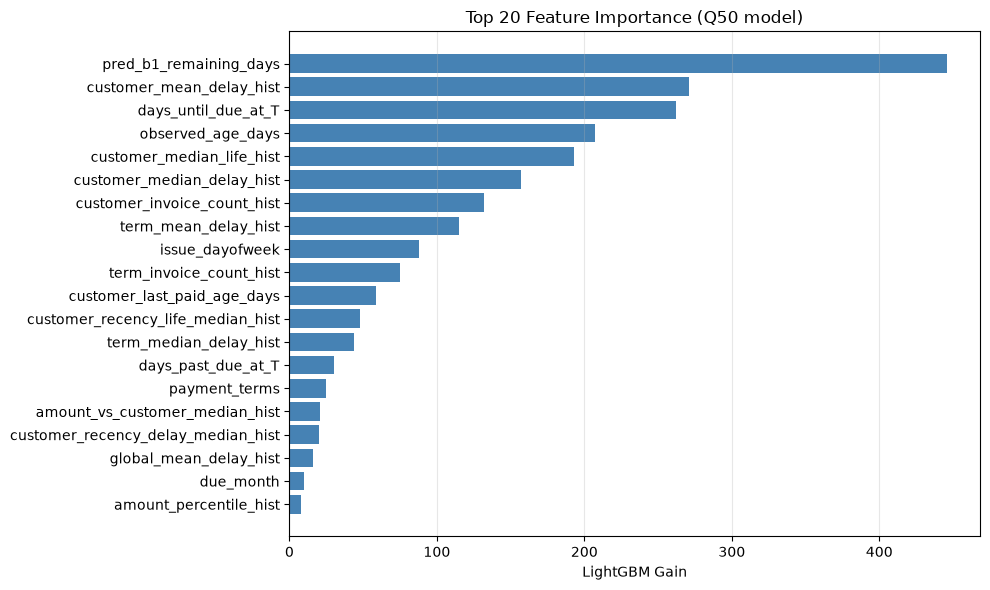

In [13]:
# ── Extract feature importance from Q50 model ─────────────────────────────
feat_imp = pd.DataFrame({
    "feature": FEATURE_COLS,
    "importance": lgbm_q50.feature_importances_,
}).sort_values("importance", ascending=False).reset_index(drop=True)

print()
print("Top 20 features:")
print(feat_imp.head(20).to_string(index=False))

# ── Plot top 20 ───────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 6))
top20 = feat_imp.head(20)
ax.barh(range(len(top20)), top20["importance"], color="steelblue")
ax.set_yticks(range(len(top20)))
ax.set_yticklabels(top20["feature"])
ax.invert_yaxis()
ax.set_xlabel("LightGBM Gain")
ax.set_title("Top 20 Feature Importance (Q50 model)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Calibration Coverage Check (Val Set)

Kiểm tra coverage [P10,P90] trên val set có đạt target 75-85% không.
Nếu lệch, CQR (notebook 04) sẽ hiệu chỉnh lại.

In [14]:
cov_q90 = (val_df[TARGET] <= val_df['pred_q90']).mean()
cov_q10 = (val_df[TARGET] >= val_df['pred_q10']).mean()
cov_int = ((val_df[TARGET] >= val_df['pred_q10']) & (val_df[TARGET] <= val_df['pred_q90'])).mean()
print('Coverage -- Validation Set')
print(f'  P(actual <= P90)       = {cov_q90:.1%}  (ideal ~90%)')
print(f'  P(actual >= P10)       = {cov_q10:.1%}  (ideal ~90%)')
print(f'  P(actual in [P10,P90]) = {cov_int:.1%}  (target 75-85%)')
if 0.75 <= cov_int <= 0.85:
    print('[OK] Coverage đạt target')
elif cov_int < 0.75:
    print('[!]  Coverage thấp -- intervals quá hẹp; CQR sẽ mở rộng')
else:
    print('[!]  Coverage cao  -- intervals quá rộng; CQR sẽ thu hẹp')

Coverage -- Validation Set
  P(actual <= P90)       = 88.6%  (ideal ~90%)
  P(actual >= P10)       = 81.7%  (ideal ~90%)
  P(actual in [P10,P90]) = 70.3%  (target 75-85%)
[!]  Coverage thấp -- intervals quá hẹp; CQR sẽ mở rộng


## 11. Visualise Predictions (Test Set Sample)

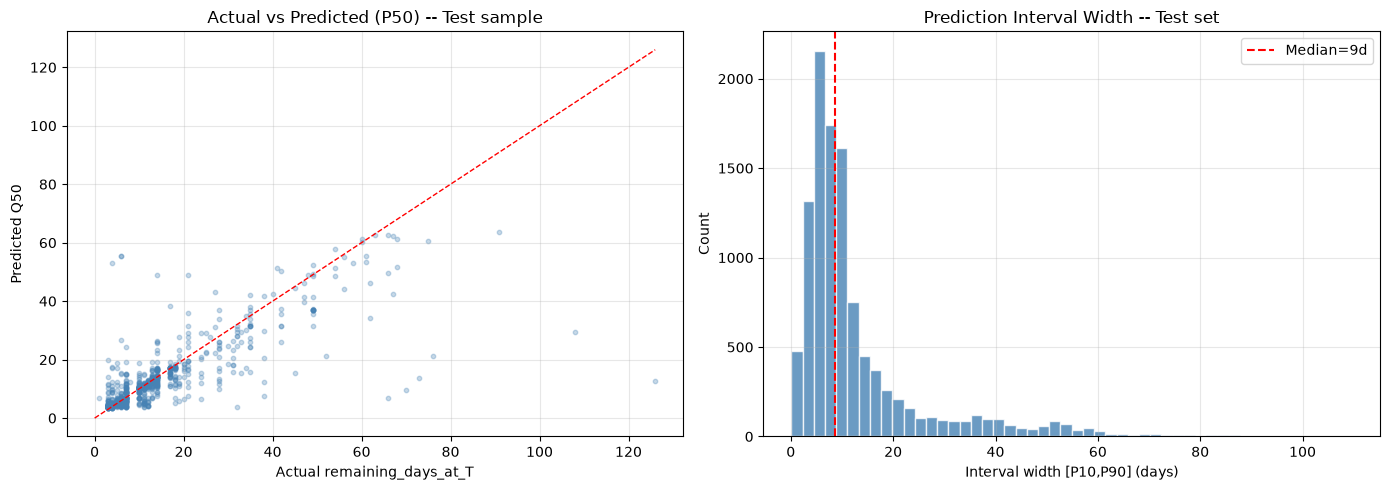

Median interval width: 9 days
P90    interval width: 31 days


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
samp = test_df.sample(min(1000, len(test_df)), random_state=SEED)
ax.scatter(samp[TARGET], samp['pred_q50'], alpha=0.3, s=10, color='steelblue')
ax.plot([0, samp[TARGET].max()], [0, samp[TARGET].max()], 'r--', lw=1)
ax.set_xlabel('Actual remaining_days_at_T'); ax.set_ylabel('Predicted Q50')
ax.set_title('Actual vs Predicted (P50) -- Test sample'); ax.grid(alpha=0.3)
ax = axes[1]
test_df['interval_width'] = test_df['pred_q90'] - test_df['pred_q10']
ax.hist(test_df['interval_width'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
ax.set_xlabel('Interval width [P10,P90] (days)'); ax.set_ylabel('Count')
ax.set_title('Prediction Interval Width -- Test set'); ax.grid(alpha=0.3)
med_iw = test_df['interval_width'].median()
ax.axvline(med_iw, color='red', linestyle='--', label=f'Median={med_iw:.0f}d')
ax.legend(); plt.tight_layout(); plt.show()
print(f'Median interval width: {med_iw:.0f} days')
print(f'P90    interval width: {test_df["interval_width"].quantile(0.9):.0f} days')


## 12. Save LightGBM Models (text format)

In [16]:
lgbm_q10.booster_.save_model(str(MODEL_DIR / 'lgbm_q10.txt'))
lgbm_q50.booster_.save_model(str(MODEL_DIR / 'lgbm_q50.txt'))
lgbm_q90.booster_.save_model(str(MODEL_DIR / 'lgbm_q90.txt'))
print('Models saved:')
for fname in ['lgbm_q10.txt', 'lgbm_q50.txt', 'lgbm_q90.txt']:
    fpath = MODEL_DIR / fname
    print(f'  {fpath}  ({fpath.stat().st_size // 1024} KB)')


Models saved:
  D:\CURRICULUM\Semester VI\Finance Project\models\lgbm_q10.txt  (688 KB)
  D:\CURRICULUM\Semester VI\Finance Project\models\lgbm_q50.txt  (219 KB)
  D:\CURRICULUM\Semester VI\Finance Project\models\lgbm_q90.txt  (3306 KB)


## 13. Inference -- Current Open Invoices

Dự báo P10/P50/P90 cho tất cả hoá đơn đang mở hiện tại.
Kết quả này chưa được calibrate -- CQR (notebook 04) sẽ hiệu chỉnh.


In [17]:
open_df = pd.read_csv(OPEN_FILE, parse_dates=['cutoff_date','issue_date','due_date'])
print(f'Current open invoices : {len(open_df):,}')
print(f'Cutoff date           : {open_df["cutoff_date"].iloc[0].date()}')

open_df['aging_bucket_ord'] = open_df['aging_bucket_at_T'].map(AGING_ORDER).fillna(0).astype(int)

# Merge B1 baseline prediction as meta-feature (D4)
bl_open_path = PROC / 'current_open_baseline_forecast.csv'
if bl_open_path.exists():
    bl_open = pd.read_csv(bl_open_path, usecols=['invoice_id','pred_b1_remaining_days'])
    open_df = open_df.merge(bl_open, on='invoice_id', how='left')
else:
    open_df['pred_b1_remaining_days'] = np.maximum(
        0.0, open_df['days_until_due_at_T'] + open_df['customer_median_delay_hist'].fillna(0)
    )

for col in FEATURE_COLS:
    if col not in open_df.columns:
        open_df[col] = 0.0

X_open    = open_df[FEATURE_COLS].values
pred_open = predict_and_rearrange(lgbm_q10, lgbm_q50, lgbm_q90, X_open)
open_df['pred_q10'] = pred_open['pred_q10'].values
open_df['pred_q50'] = pred_open['pred_q50'].values
open_df['pred_q90'] = pred_open['pred_q90'].values

for q, col in [('pred_q10','pred_paid_date_q10'),('pred_q50','pred_paid_date_q50'),
               ('pred_q90','pred_paid_date_q90')]:
    open_df[col] = (open_df['cutoff_date'] +
                    pd.to_timedelta(open_df[q].apply(np.ceil).astype(int), unit='D'))

disp = ['invoice_id','customer_id','amount','is_overdue_at_T',
        'pred_q10','pred_q50','pred_q90','pred_paid_date_q50']
print()
print('Top 10 invoices by predicted remaining days:')
print(open_df.sort_values('pred_q50',ascending=False).head(10)[disp].to_string(index=False))


Current open invoices : 9,681
Cutoff date           : 2020-05-22



Top 10 invoices by predicted remaining days:
 invoice_id customer_id    amount  is_overdue_at_T  pred_q10  pred_q50  pred_q90 pred_paid_date_q50
 2960631522   140106181 14375.500                1    27.728    48.319    48.819         2020-07-10
 1930850524   200418007  3024.000                0    24.794    45.345    52.722         2020-07-07
 1930858188   200743996  2215.510                0    24.046    45.345    55.675         2020-07-07
 2960617807   140106227 14401.310                1    21.789    44.479    45.618         2020-07-06
 1930842496   200418007 53289.600                0    30.131    44.189    52.753         2020-07-06
 1930832700   200418007  4569.600                0    29.781    42.430    49.968         2020-07-04
 2960631220   140106181  6216.750                1    27.288    41.615    46.634         2020-07-03
 1930829076   200762301 24216.280                0    33.605    40.472    43.541         2020-07-02
 1930669505   200540723 85503.600                0    

## 14. Save All Outputs (for CQR -- Notebook 04)

In [18]:
# 1. Rolling snapshot predictions
all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
out_cols = [
    'cutoff_date','time_split','invoice_id','customer_id',
    'amount','due_date','target_paid_date', TARGET,
    'pred_q10','pred_q50','pred_q90','quantile_crossed',
    'pred_b1_remaining_days','pred_b1r_remaining_days',
    'is_overdue_at_T','customer_history_sufficient','aging_bucket_at_T',
]
all_df[out_cols].to_csv(OUT_SNAP_PRED, index=False)
print(f'[1] {OUT_SNAP_PRED.name}  ({len(all_df):,} rows)')

# 2. Current open forecast
open_out = ['invoice_id','customer_id','name_customer',
            'cutoff_date','issue_date','due_date','amount',
            'is_overdue_at_T','aging_bucket_at_T','customer_history_sufficient',
            'pred_q10','pred_q50','pred_q90',
            'pred_paid_date_q10','pred_paid_date_q50','pred_paid_date_q90',
            'pred_b1_remaining_days']
open_df[[c for c in open_out if c in open_df.columns]].to_csv(OUT_CURR_FCST, index=False)
print(f'[2] {OUT_CURR_FCST.name}  ({len(open_df):,} rows)')

# 3. Metrics CSV
rows = []
for split, df_, bl_ in [('train',train_df,baseline_train),
                         ('val',  val_df,  baseline_val),
                         ('test', test_df, baseline_test)]:
    m = compute_metrics(df_, prefix='')
    rows.append({'split':split,'n_rows':len(df_),
                 'lgbm_mae_q50':round(m['mae_q50'],4),
                 'lgbm_pinball_q10':round(m['pinball_q10'],4),
                 'lgbm_pinball_q50':round(m['pinball_q50'],4),
                 'lgbm_pinball_q90':round(m['pinball_q90'],4),
                 'lgbm_cov_interval_80':round(m['cov_interval_80'],4),
                 'b1_mae':round(bl_['mae_b1'],4),
                 'b1r_mae':round(bl_['mae_b1r'],4),
                 'improvement_vs_b1_pct':round((bl_['mae_b1']-m['mae_q50'])/bl_['mae_b1']*100,2)})
met_df = pd.DataFrame(rows)
met_df.to_csv(OUT_METRICS, index=False)
print(f'[3] {OUT_METRICS.name}')
print()
print(met_df.to_string(index=False))


[1] lgbm_snapshot_predictions.csv  (76,151 rows)
[2] lgbm_current_forecast.csv  (9,681 rows)
[3] lgbm_metrics.csv

split  n_rows  lgbm_mae_q50  lgbm_pinball_q10  lgbm_pinball_q50  lgbm_pinball_q90  lgbm_cov_interval_80  b1_mae  b1r_mae  improvement_vs_b1_pct
train   50083         4.156             0.763             2.078             0.810                 0.813   5.158    5.542                 19.430
  val   15162         2.858             0.583             1.429             0.923                 0.703   3.505    4.059                 18.450
 test   10906         3.529             0.697             1.764             1.454                 0.756   4.027    4.602                 12.380


## Summary and Go/No-Go Gate

### Pipeline position
```
01_data_preparation_eda --> 02_payment_baselines --> [03_lightgbm_payment_quantiles] --> 04_cqr --> 05_montecarlo
```

### Go/No-Go rule (../docs/reports/agent1_implementation_review.md Tầng 9)
- MAE improvement vs B1 **>= 10%** on test set --> **PASS** --> sang CQR (notebook 04)
- MAE improvement vs B1 **< 10%** on test set  --> **FAIL** --> debug

### Outputs saved
| File | Dùng cho |
|---|---|
| `lgbm_snapshot_predictions.csv` | CQR tính nonconformity scores trên val set |
| `lgbm_current_forecast.csv` | Inference hiện tại (chưa calibrated) |
| `lgbm_metrics.csv` | Checkpoint gate |
| `models/lgbm_q{10,50,90}.txt` | Production inference |

### Tài liệu tham chiếu
| Quyết định | Nguồn |
|---|---|
| LightGBM algorithm | Ke et al. NeurIPS 2017 (`lightgbm_efficient_gradient_boosting.pdf`) |
| Quantile regression loss | Koenker & Bassett 1978 (`regression_quantiles.pdf`) |
| CQR bước tiếp | Romano et al. 2019 (`conformalized_quantile_regression.pdf`) |
| Pipeline spec Tầng 5 | `../docs/reports/agent1_implementation_review.md` |
| Feature design (as-of) | `reference_notebooks/01_data_preparation_eda.ipynb` |
| Baseline B1/B1R | `reference_notebooks/02_payment_baselines.ipynb` |
| Monotone rearrangement | Chernozhukov et al. Econometrica 2010 |
